# ۰۸ - تحلیل رضایت مشتریان

پاسخ به سؤال‌های بخش ۱۰ صورت‌مسئله: توزیع امتیازها، رضایت در دسته‌بندی‌ها و روند زمانی رضایت.

## ۲. سؤال‌های کسب‌وکاری

1. توزیع امتیاز نظرها چگونه است؟
2. میانگین امتیاز و سهم امتیازهای ۴ و ۵ و ۱ و ۲ چقدر است؟
3. کدام دسته‌بندی‌ها بالاترین و پایین‌ترین میانگین امتیاز را دارند؟
4. تعداد نظر هر دسته‌بندی چه اهمیتی دارد؟
5. روند میانگین امتیاز در طول زمان چگونه است؟

## ۱. عنوان و هدف

پاسخ به سؤال‌های بخش ۱۰ صورت‌مسئله: توزیع امتیازها، رضایت در دسته‌بندی‌ها و روند زمانی رضایت.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from olist_analysis import metrics as M
from olist_analysis.config import FIGURES_DIR, REPORTS_DIR, TABLES_DIR
from olist_analysis.font_utils import persian_available
from olist_analysis.features import load_dataset
from olist_analysis.pipeline import load_headline

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

ds = load_dataset()
headline = load_headline()
print("Persian font registered for charts:", persian_available())
print(f"orders={len(ds.orders):,}  items={len(ds.items):,}  "
      f"delivered={len(ds.delivered):,}  reviewed={len(ds.reviews_per_order):,}")


Persian font registered for charts: True
orders=99,441  items=112,650  delivered=96,470  reviewed=98,673


## ۴. روش محاسبه

مبنای محاسبه، جدول «یک نظر برای هر سفارش» است (۹۸٬۶۷۳ سفارش). برای هر سفارش جدیدترین نظر بر اساس `review_answer_timestamp` نگه داشته می‌شود؛ این کار از تکثیر امتیاز در اتصال جلوگیری می‌کند.

## ۶. تحلیل عددی

### ۱۰.۱ و ۱۰.۲ توزیع امتیازها

In [2]:
display(M.review_score_distribution(ds))

,review_score,n_reviews,pct_reviews,cum_pct
0,1,11363,11.5158,11.5158
1,2,3131,3.1731,14.6889
2,3,8133,8.2424,22.9313
3,4,19038,19.2940,42.2253
4,5,57008,57.7747,100.0000


In [3]:
display(pd.Series(M.satisfaction_kpis(ds), name="value"))

n_orders_with_review        98673.0000
n_orders_without_review       768.0000
pct_orders_with_review         99.2277
mean_score                      4.0864
median_score                    5.0000
pct_4_or_5                     77.0687
pct_5                          57.7747
pct_1_or_2                     14.6889
pct_1                          11.5158
n_orders                    99441.0000
n_items                    112650.0000
Name: value, dtype: float64

### ۱۰.۳ ده دسته‌بندی با بالاترین میانگین امتیاز

In [4]:
display(M.category_satisfaction_ranked(ds, "best", 10))

,category_label,n_orders,n_reviews,mean_score,revenue,mean_item_price,pct_revenue,overall_mean_score,score_vs_overall,meets_min_reviews
0,books_general_interest,512,508,4.46,46856.88,86.61,0.3447,4.1,0.37,True
1,costruction_tools_tools,97,94,4.43,15903.95,148.95,0.1170,4.1,0.33,True
2,books_technical,260,257,4.40,19096.06,71.30,0.1405,4.1,0.30,True
3,food_drink,227,226,4.38,15179.48,59.69,0.1117,4.1,0.28,True
4,luggage_accessories,1034,1030,4.33,140429.98,130.71,1.0332,4.1,0.24,True
5,books_imported,53,53,4.32,4639.85,77.46,0.0341,4.1,0.22,True
6,small_appliances_home_oven_and_coffee,75,75,4.29,47445.71,626.25,0.3491,4.1,0.20,True
7,food,450,445,4.28,29393.41,59.95,0.2163,4.1,0.18,True
8,stationery,2311,2295,4.25,230943.23,94.86,1.6992,4.1,0.15,True
9,pet_shop,1710,1701,4.24,214315.41,114.94,1.5768,4.1,0.14,True


### ۱۰.۴ ده دسته‌بندی با پایین‌ترین میانگین امتیاز

In [5]:
display(M.category_satisfaction_ranked(ds, "worst", 10))

,category_label,n_orders,n_reviews,mean_score,revenue,mean_item_price,pct_revenue,overall_mean_score,score_vs_overall,meets_min_reviews
0,office_furniture,1273,1263,3.62,273960.70,168.26,2.0157,4.1,-0.48,True
1,fashio_female_clothing,39,39,3.69,2803.64,63.37,0.0206,4.1,-0.40,True
2,fashion_male_clothing,112,111,3.70,10797.82,82.37,0.0794,4.1,-0.39,True
3,furniture_mattress_and_upholstery,38,38,3.82,4368.08,114.95,0.0321,4.1,-0.28,True
4,audio,350,347,3.84,50688.50,142.37,0.3729,4.1,-0.26,True
5,construction_tools_safety,167,166,3.85,40544.52,216.64,0.2983,4.1,-0.25,True
6,home_confort,397,395,3.86,58572.04,139.64,0.4309,4.1,-0.24,True
7,fixed_telephony,217,214,3.90,59583.00,165.13,0.4384,4.1,-0.19,True
8,fashion_underwear_beach,121,120,3.93,9541.55,75.83,0.0702,4.1,-0.16,True
9,bed_bath_table,9417,9313,3.97,1036988.68,96.03,7.6296,4.1,-0.13,True


### ۱۰.۵ اهمیت تعداد نظر: دسته‌بندی‌های با نمونه کوچک

In [6]:
display(M.low_volume_categories(ds))

,category_label,n_orders,n_reviews,mean_score,revenue
0,security_and_services,2,2,2.50,283.29
1,pc_gamer,8,8,3.12,1545.95
2,fashion_childrens_clothes,8,8,4.50,569.85
3,la_cuisine,13,12,4.25,2054.99
4,cds_dvds_musicals,12,12,4.67,730.00
5,portateis_cozinha_e_preparadores_de_alimentos,14,14,3.43,3968.53
6,home_comfort_2,24,23,3.83,760.27
7,arts_and_craftmanship,23,23,4.17,1814.01
8,fashion_sport,27,27,4.26,2119.51
9,diapers_and_hygiene,27,27,3.74,1567.59


### ۱۰.۷ روند زمانی میانگین امتیاز

In [7]:
display(M.monthly_satisfaction_trend(ds))

,purchase_ym,n_reviews,mean_score,pct_1_or_2,in_core_window,order_month
0,2016-09,4,1.00,100.0000,False,2016-09-01
1,2016-10,319,3.56,29.1536,False,2016-10-01
2,2016-12,1,5.00,0.0000,False,2016-12-01
3,2017-01,790,4.06,15.5696,True,2017-01-01
4,2017-02,1768,4.02,16.1765,True,2017-02-01
5,2017-03,2661,4.07,14.1676,True,2017-03-01
6,2017-04,2387,4.04,15.4587,True,2017-04-01
7,2017-05,3666,4.14,12.7660,True,2017-05-01
8,2017-06,3218,4.15,12.7408,True,2017-06-01
9,2017-07,3990,4.18,12.2055,True,2017-07-01


## ۷. نمودارها

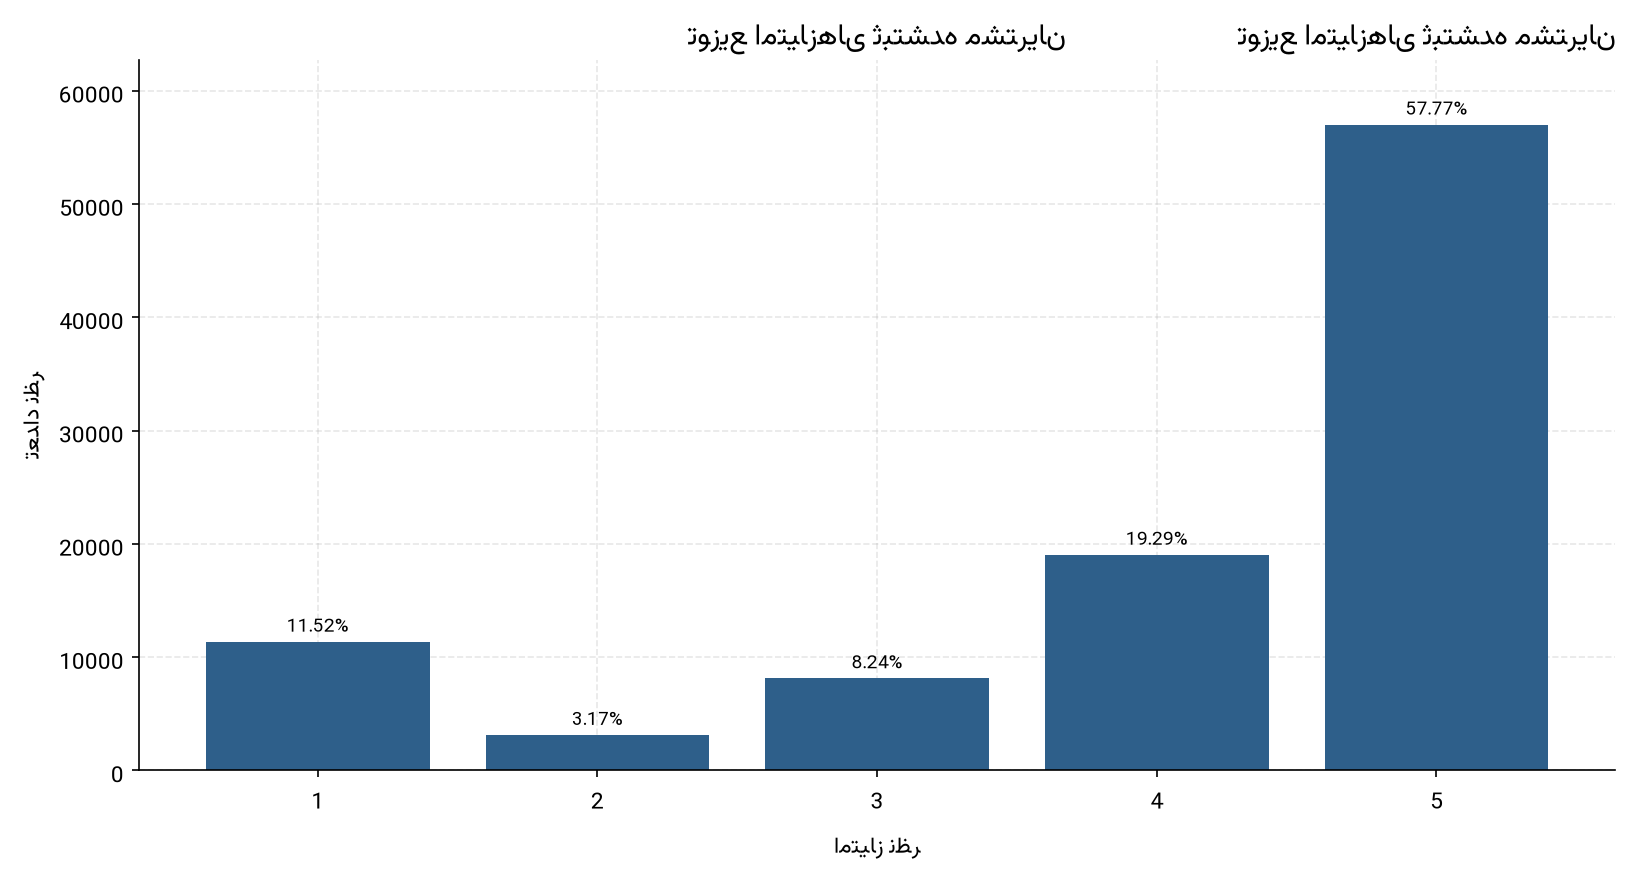

نمودار ۱۹ - توزیع امتیازها؛ ۵ پرتکرارترین و ۱ کمترین رضایت


In [8]:
display(Image(filename=str(FIGURES_DIR / "fig_19_review_scores.png"), width=920))
caption = FIGURES_DIR / "fig_19_review_scores.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

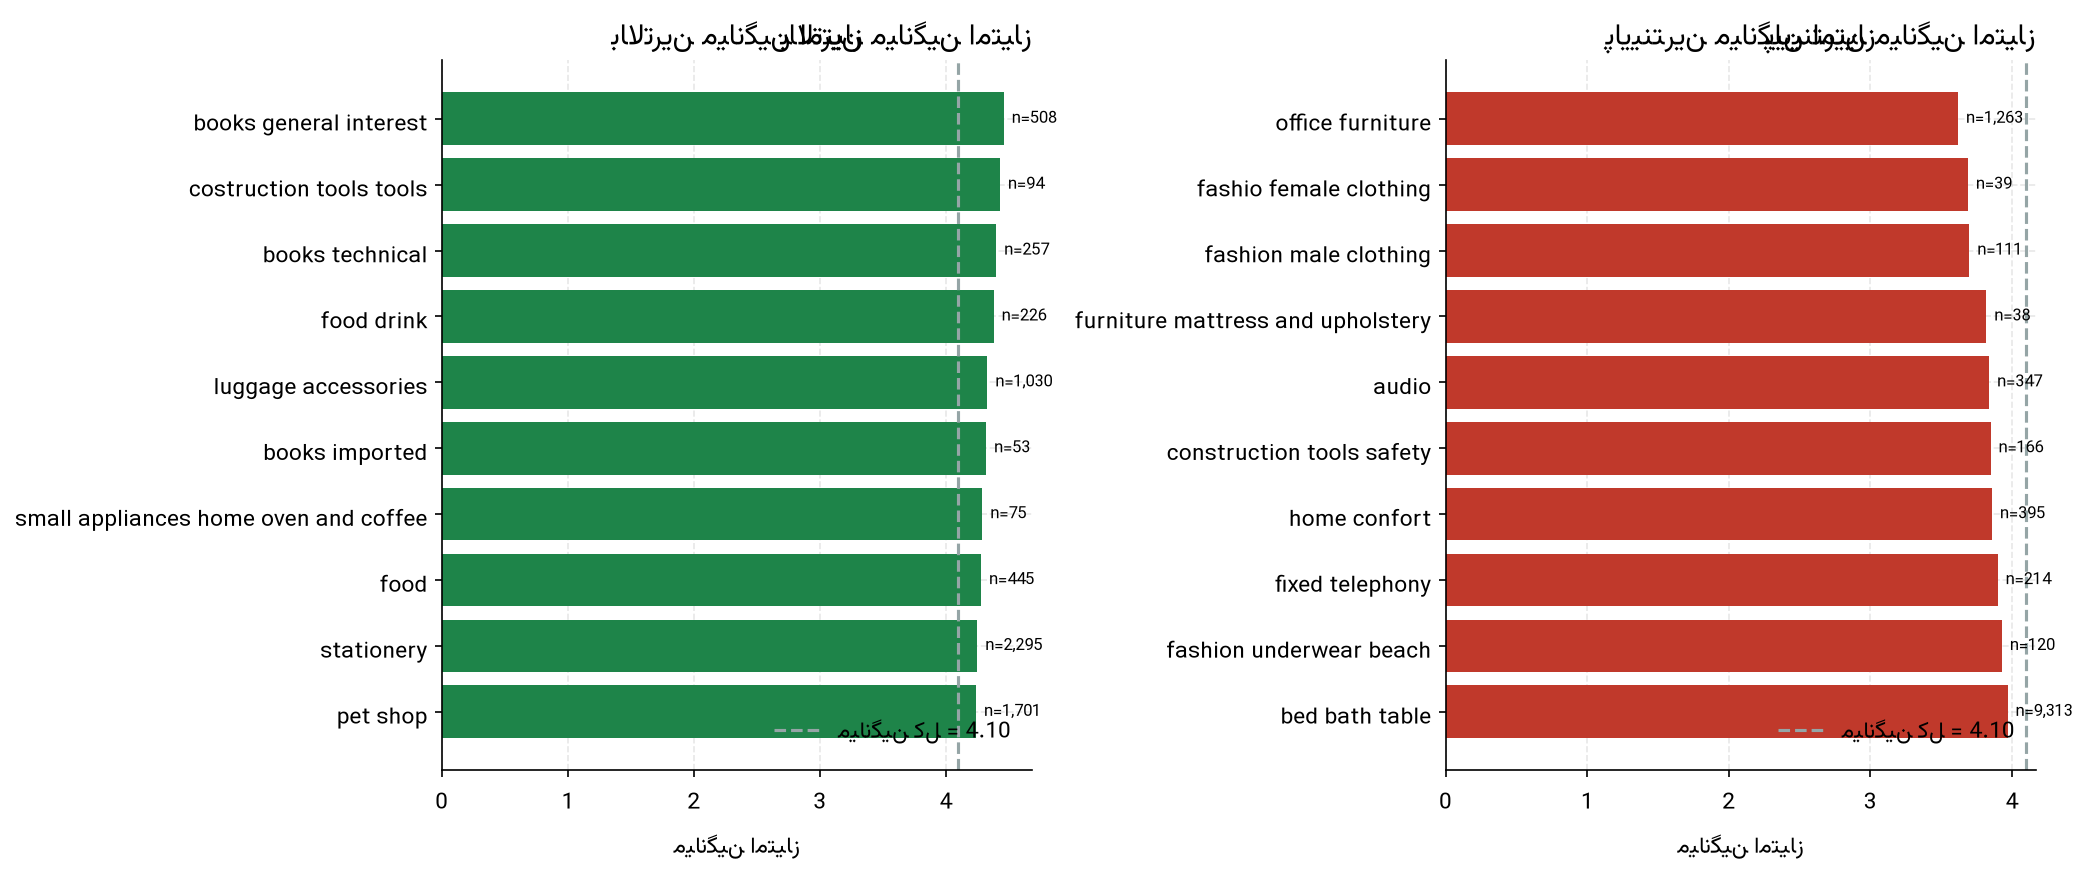

نمودار ۲۰ - دستهبندیها با بالاترین و پایینترین میانگین امتیاز (حداقل ۳۰ نظر)


In [9]:
display(Image(filename=str(FIGURES_DIR / "fig_20_category_scores.png"), width=920))
caption = FIGURES_DIR / "fig_20_category_scores.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

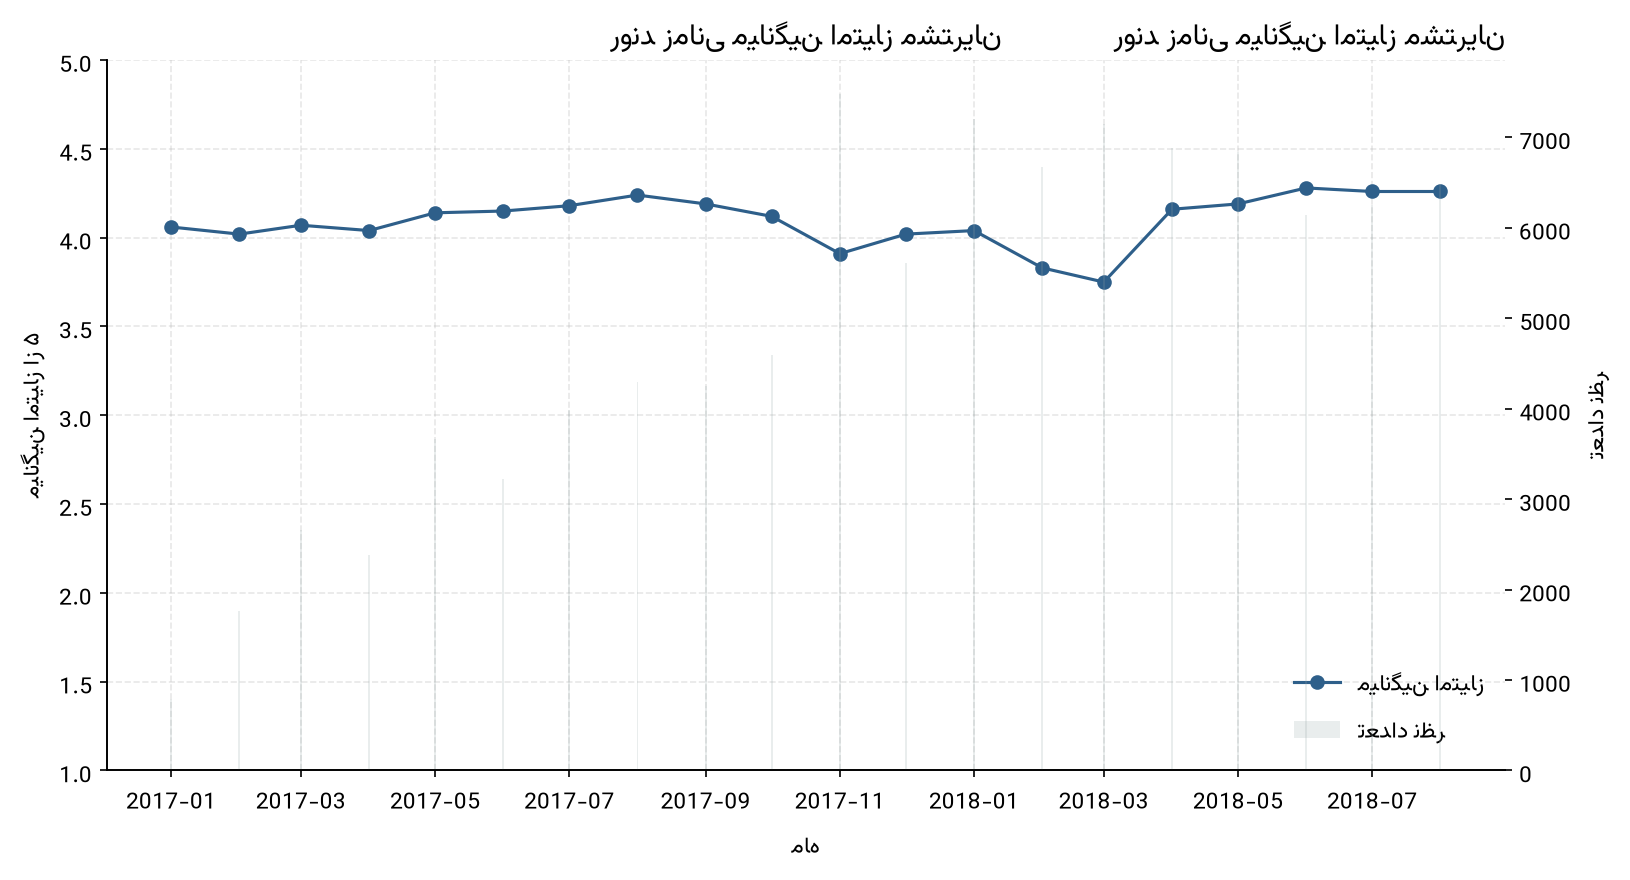

نمودار ۲۱ - روند میانگین امتیاز مشتریان در پنجره تحلیلی


In [10]:
display(Image(filename=str(FIGURES_DIR / "fig_21_monthly_score_trend.png"), width=920))
caption = FIGURES_DIR / "fig_21_monthly_score_trend.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

## ۸. یافته‌های واقعی

- میانگین امتیاز مشتریان ۴.۰۹ از ۵ است؛ ۷۷.۰۷ درصد نظرات امتیاز ۴ یا ۵ و ۱۴.۶۹ درصد امتیاز ۱ یا ۲ داده‌اند.
- امتیاز ۵ با ۵۷٬۰۰۸ نظر پرتکرارترین و امتیاز ۲ با ۳٬۱۳۱ نظر کم‌تکرارترین است؛ ولی امتیاز ۱ با ۱۱٬۳۶۳ نظر از امتیاز ۲ و ۳ بیشتر است.
- پرترین میانگین‌ها به دسته‌بندی‌های کوچک و کتاب‌محور تعلق دارد: `books_general_interest` با ۴.۴۶ و ۵۰۸ نظر.
- پایین‌ترین میانگین‌ها به دسته‌بندی‌های بزرگ مبلمان و لوازم خانه تعلق دارد: `office_furniture` با ۳.۶۲ و ۱٬۲۶۳ نظر و اختلاف منفی ۰.۴۸ با میانگین کل.
- ۱۱ دسته‌بندی کمتر از ۳۰ نظر دارند؛ بهترین/بدترین رتبه‌ها در آن‌ها قابل تعمیم نیست.

## ۹. تفسیر کسب‌وکاری

رضایت کلی بالا است، اما یک دنباله منفی پایدار وجود دارد: حدود ۱۴.۷ درصد مشتریان امتیاز ۱ یا ۲ داده‌اند. دسته‌بندی‌های پرحجم با امتیاز پایین (به‌ویژه مبلمان اداری) بالاترین اولویت بررسی کیفی را دارند.

## ۱۰. محدودیت‌های تحلیل

تنها ۷۶۸ سفارش نظر ثبت‌شده ندارند (۹۹.۲۳ درصد سفارش‌ها دارای نظر هستند)، بنابراین سوگیری پاسخ‌ندادن مشکل جدی نیست؛ اما متن نظرات در تحلیل کمّی استفاده نشده و علت نارضایتی قابل استخراج نیست.

## ۱۱. نتیجه‌گیری

وضعیت رضایت مشتریان خوب است، اما بهبود نیازمند تمرکز روی دسته‌بندی‌ها و سفارش‌هایی است که امتیاز پایین می‌گیرند.